# 05 Feature engineering and final models

This notebook goes from the notebook 01 features to our final submission (**AIcrowd F1 = 0.446**), which
`run.py` reproduces. Every number comes from the same **stratified 5-fold cross-validation**, with the decision
threshold tuned for F1 on the out-of-fold scores.

| Section | Question | Answer |
|---|---|---|
| 1 | Why tune the threshold? | at 0.5 least squares predicts almost no positives (F1 0.09 → 0.41) |
| 2 | Can we oversample before splitting? | no: it leaks training rows into validation (F1 0.70, meaningless) |
| 3 | Ridge on the notebook 01 features | F1 0.412, λ barely matters |
| 4 | Better features | three dropped feature groups, squares, age/sex interactions: 0.411 → 0.428 |
| 5 | Class imbalance | mild undersampling helps ridge: 0.432 (AIcrowd 0.441) |
| 6 | Least squares instead of ridge | needs redundant columns removed; weighted least squares 0.431 (AIcrowd 0.442) |
| 7 | Logistic regression | Newton's method, same objective as `reg_logistic_regression`: 0.433 (**AIcrowd 0.446**) |
| 8 | Final model | the `run.py` pipeline and its submission |

The helper modules are in `code/`: `feature_engineering.py` (configurable notebook 01 cleaning, extra features,
Newton solver), `cross_validation.py`, `metrics.py`. Run time: about 20 minutes.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "implementations.py").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))           # implementations.py
sys.path.insert(0, str(PROJECT_ROOT / "code"))  # helper modules

import feature_engineering as fe
import implementations as impl
from cross_validation import build_k_indices, cross_validation, random_oversample, random_undersample
from helpers import create_csv_submission
from metrics import compute_metrics, predict_labels

# NumPy 2.0 with Apple's Accelerate BLAS emits spurious matmul warnings on finite data.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

K_FOLD = 5
SEED = 1
GROUPS = ("redundant", "risk_management", "optional_modules")
INTERACT = ("_AGE80", "SEX=2")

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2, "font.size": 10,
})

In [2]:
start = time.time()
raw = fe.load_raw(PROJECT_ROOT / "dataset")   # parses the CSVs once, then uses a cache
decoded = fe.decode_missing(raw)
y = raw["y_train"]
k_indices = build_k_indices(y, K_FOLD, seed=SEED)


def features(keep_groups=(), **kwargs):
    # Train / test matrices with the bias column.
    x_tr, x_te, _ = fe.build_features(raw, keep_groups=keep_groups, decoded=decoded, **kwargs)
    return np.c_[np.ones(len(x_tr)), x_tr], np.c_[np.ones(len(x_te)), x_te]


def undersample(ratio):
    # Training-fold rebalancing: all positives + `ratio` negatives per positive (None = all rows).
    return None if ratio is None else (lambda x, y, seed: random_undersample(x, y, seed, ratio=ratio))


def run(tx, model, params, ratio=None, label="", threshold=None):
    # 5-fold CV on the shared folds; prints one line and returns the result.
    t = time.time()
    r = cross_validation(y, tx, model, params, k_indices, resample_fn=undersample(ratio),
                         threshold=threshold, seed=SEED)
    print(f"{label:<46} F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   P = {r['precision_mean']:.3f}  "
          f"R = {r['recall_mean']:.3f}   ({time.time() - t:.0f}s)")
    return r


tx_base, _ = features()   # notebook 01 features
print(f"{len(y)} train rows ({y.mean():.2%} positive), {len(raw['test_ids'])} test rows; "
      f"notebook 01 features: {tx_base.shape[1]} columns  ({time.time() - start:.0f}s)")

328135 train rows (8.83% positive), 109379 test rows; notebook 01 features: 178 columns  (50s)


## 1. F1 and the decision threshold

With 9% positives, predicting "no heart disease" for everyone gives 91% accuracy and F1 = 0, which is why models
are compared on F1. Least squares regresses on y ∈ {0, 1}, so `tx @ w` is roughly a probability, and the usual
cut at 0.5 almost never predicts a positive. Tuning the threshold for F1 on the out-of-fold scores changes everything.

always 0   accuracy = 0.9117   F1 = 0.0000
always 1   accuracy = 0.0883   F1 = 0.1623

least squares, threshold 0.5                   F1 = 0.0908 ± 0.0038   P = 0.664  R = 0.049   (1s)
least squares, tuned threshold                 F1 = 0.4107 ± 0.0069   P = 0.333  R = 0.535   (1s)
tuned threshold = 0.210


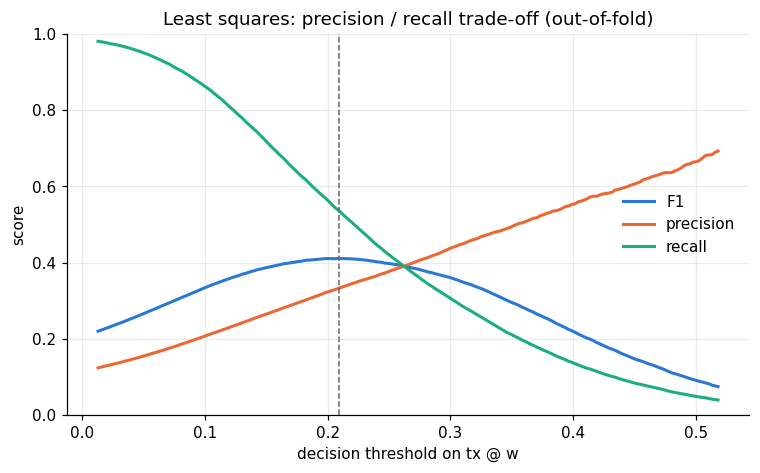

In [3]:
for name, y_pred in {"always 0": np.zeros_like(y), "always 1": np.ones_like(y)}.items():
    m = compute_metrics(y, y_pred)
    print(f"{name:<10} accuracy = {m['accuracy']:.4f}   F1 = {m['f1']:.4f}")
print()
ls_fixed = run(tx_base, "least_squares", {}, threshold=0.5, label="least squares, threshold 0.5")
ls_tuned = run(tx_base, "least_squares", {}, label=f"least squares, tuned threshold")
print(f"tuned threshold = {ls_tuned['threshold']:.3f}")

scores = ls_tuned["oof_scores"]
thresholds = np.linspace(np.quantile(scores, 0.30), np.quantile(scores, 0.995), 200)
curves = np.array([[compute_metrics(y, predict_labels(scores, t))[k] for k in ("f1", "precision", "recall")]
                   for t in thresholds])
fig, ax = plt.subplots()
for (label, color), values in zip([("F1", BLUE), ("precision", ORANGE), ("recall", AQUA)], curves.T):
    ax.plot(thresholds, values, color=color, label=label)
ax.axvline(ls_tuned["threshold"], color="0.4", linestyle="--", linewidth=1)
ax.set_xlabel("decision threshold on tx @ w")
ax.set_ylabel("score")
ax.set_ylim(0, 1)
ax.set_title("Least squares: precision / recall trade-off (out-of-fold)")
ax.legend(frameon=False, loc="center right")
plt.show()

## 2. Stratified folds, and why rebalancing must happen inside the folds

`build_k_indices` puts every row in exactly one fold and keeps the 8.8% positive rate in each fold. Any
rebalancing (sections 5-7) is applied to the **training folds only**. Oversampling *before* splitting puts
copies of the same positive row in the training and the validation fold, so the model is scored partly on rows
it has memorized, and the validation folds no longer have the real class ratio:

In [4]:
print("positive rate per fold:", ", ".join(f"{y[idx].mean():.4%}" for idx in k_indices))

# Leaky: duplicate positives until they are 1/3 of the rows, THEN split.
tx_over, y_over = random_oversample(tx_base, y, seed=SEED, ratio=0.5)
k_over = build_k_indices(y_over, K_FOLD, seed=SEED)
leaky = cross_validation(y_over, tx_over, "ridge_regression", {"lambda_": 1e-3}, k_over)
del tx_over
# Correct: split first, then oversample the training folds only (same ratio).
correct = cross_validation(y, tx_base, "ridge_regression", {"lambda_": 1e-3}, k_indices,
                           resample_fn=lambda x, y, seed: random_oversample(x, y, seed, ratio=0.5))
print(f"oversample THEN split (leaky):   F1 = {leaky['f1_mean']:.4f}   (validation folds {y_over.mean():.0%} positive)")
print(f"split THEN oversample (correct): F1 = {correct['f1_mean']:.4f}   (validation folds {y.mean():.1%} positive)")

positive rate per fold: 8.8302%, 8.8302%, 8.8302%, 8.8302%, 8.8302%
oversample THEN split (leaky):   F1 = 0.7028   (validation folds 33% positive)
split THEN oversample (correct): F1 = 0.4206   (validation folds 8.8% positive)


## 3. Ridge regression on the notebook 01 features

Ridge minimizes MSE + λ‖w‖² in closed form. With N ≈ 330k rows and 178 columns there is little to regularize:
F1 is flat for every λ up to about 1e-2.

best λ = 1e-02: F1 = 0.4120 ± 0.0061


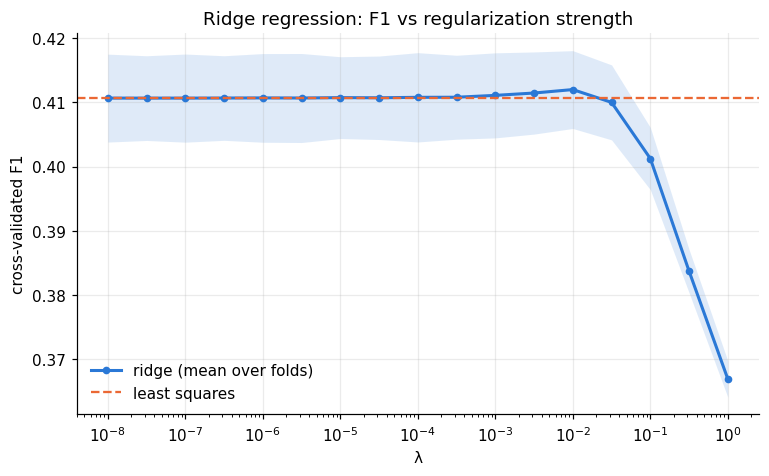

In [5]:
lambdas = np.logspace(-8, 0, 17)
ridge_base = {lam: cross_validation(y, tx_base, "ridge_regression", {"lambda_": lam}, k_indices) for lam in lambdas}
best_lambda = max(ridge_base, key=lambda lam: ridge_base[lam]["f1_mean"])
print(f"best λ = {best_lambda:.0e}: F1 = {ridge_base[best_lambda]['f1_mean']:.4f} ± {ridge_base[best_lambda]['f1_std']:.4f}")

means = np.array([ridge_base[lam]["f1_mean"] for lam in lambdas])
stds = np.array([ridge_base[lam]["f1_std"] for lam in lambdas])
fig, ax = plt.subplots()
ax.fill_between(lambdas, means - stds, means + stds, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(lambdas, means, color=BLUE, marker="o", markersize=4, label="ridge (mean over folds)")
ax.axhline(ls_tuned["f1_mean"], color=ORANGE, linestyle="--", linewidth=1.5, label="least squares")
ax.set_xscale("log")
ax.set_xlabel("λ")
ax.set_ylabel("cross-validated F1")
ax.set_title("Ridge regression: F1 vs regularization strength")
ax.legend(frameon=False, loc="lower left")
plt.show()

## 4. Better features

Every linear model we tried on the notebook 01 features (least squares, ridge, logistic regression, with or
without rebalancing) lands at 0.41-0.42: the limit is the information in the features. Notebook 01 keeps only 45
of the 321 raw columns and drops whole groups by hand. Adding each group back one at a time and keeping those that
help (a greedy forward selection) selects three of them:

- `redundant`: e.g. the 13 age bands `_AGEG5YR` (a non-linear age effect), income, education, cholesterol;
- `risk_management`: e.g. blood-pressure medication, diet advice;
- `optional_modules`: questions only asked in some states.

Two groups are **not** used: `follow_up` and `data_quality` add nothing, and `cvd_care` (heart-attack rehab,
aspirin to prevent a heart attack, ...) is mostly answered by people who already had a cardiovascular event, so it
may leak the label. On top of the groups:

- standardized **squares** of the numeric columns (squares of one-hot columns would only duplicate them);
- **interactions** with age and sex: every original column multiplied by age and by sex, so a risk factor can
  weigh differently for older people or for women.

Each row adds one change to the previous one (ridge, λ = 1e-3, undersampling 1:1 from the second row on).

In [6]:
steps = [
    ("notebook 01 features", (), {}, None),
    ("+ undersample 1:1", (), {}, 1.0),
    ("+ 3 feature groups", GROUPS, {}, 1.0),
    ("+ squares of numeric columns", GROUPS, {"square_numeric": True}, 1.0),
    ("+ age and sex interactions", GROUPS, {"square_numeric": True, "interact_with": INTERACT}, 1.0),
]
step_results = []
for label, groups, kwargs, ratio in steps:
    tx, _ = features(groups, **kwargs)
    step_results.append((label, run(tx, "ridge_regression", {"lambda_": 1e-3}, ratio, f"{label} (D = {tx.shape[1]})")))
del tx

tx, tx_test = features(GROUPS, square_numeric=True, interact_with=INTERACT)   # final features
print(f"\nfinal features: {tx.shape[1]} columns")

notebook 01 features (D = 178)                 F1 = 0.4111 ± 0.0066   P = 0.336  R = 0.531   (1s)
+ undersample 1:1 (D = 178)                    F1 = 0.4213 ± 0.0050   P = 0.354  R = 0.519   (1s)
+ 3 feature groups (D = 816)                   F1 = 0.4255 ± 0.0044   P = 0.355  R = 0.532   (4s)
+ squares of numeric columns (D = 873)         F1 = 0.4258 ± 0.0039   P = 0.352  R = 0.540   (4s)
+ age and sex interactions (D = 1236)          F1 = 0.4278 ± 0.0061   P = 0.363  R = 0.521   (15s)

final features: 1236 columns


## 5. Class imbalance: λ × undersampling ratio for ridge

`ratio` = negatives kept per positive in the training folds. Full balancing (1:1) throws away 90% of the negatives
and now *hurts*; a milder ratio helps.

      λ     none      1:1    1:1.5      1:2      1:3      1:5
 0.0001   0.4292   0.4260   0.4294   0.4300   0.4306   0.4314
  0.001   0.4294   0.4278   0.4306   0.4308   0.4316   0.4317
   0.01   0.4285   0.4275   0.4294   0.4299   0.4305   0.4303

best: λ = 0.001, undersample 1:5: F1 = 0.4317 ± 0.0045


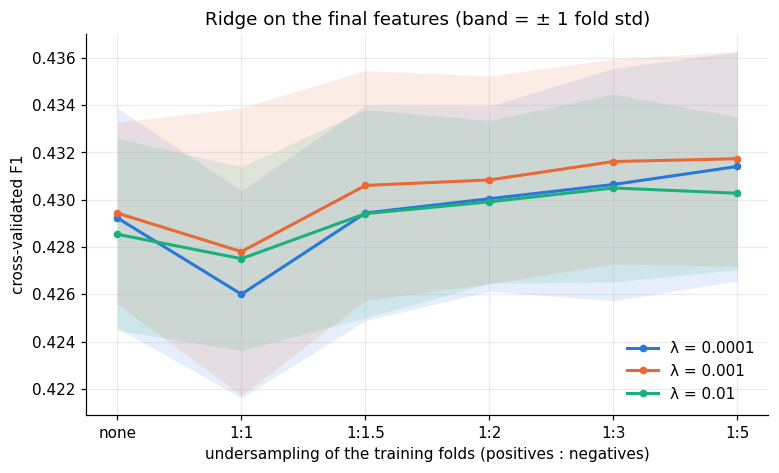

In [7]:
lambdas_final = [1e-4, 1e-3, 1e-2]
ratios = [None, 1.0, 1.5, 2.0, 3.0, 5.0]
ridge_grid = {(lam, r): cross_validation(y, tx, "ridge_regression", {"lambda_": lam}, k_indices,
                                         resample_fn=undersample(r), seed=SEED)
              for lam in lambdas_final for r in ratios}
ratio_label = lambda r: "none" if r is None else f"1:{r:g}"
print(f"{'λ':>7} " + " ".join(f"{ratio_label(r):>8}" for r in ratios))
for lam in lambdas_final:
    print(f"{lam:>7g} " + " ".join(f"{ridge_grid[(lam, r)]['f1_mean']:>8.4f}" for r in ratios))
RIDGE_BEST = max(ridge_grid, key=lambda key: ridge_grid[key]["f1_mean"])
print(f"\nbest: λ = {RIDGE_BEST[0]:g}, undersample {ratio_label(RIDGE_BEST[1])}: "
      f"F1 = {ridge_grid[RIDGE_BEST]['f1_mean']:.4f} ± {ridge_grid[RIDGE_BEST]['f1_std']:.4f}")

fig, ax = plt.subplots()
x_pos = np.arange(len(ratios))
for lam, color in zip(lambdas_final, [BLUE, ORANGE, AQUA]):
    means = np.array([ridge_grid[(lam, r)]["f1_mean"] for r in ratios])
    stds = np.array([ridge_grid[(lam, r)]["f1_std"] for r in ratios])
    ax.fill_between(x_pos, means - stds, means + stds, color=color, alpha=0.12, linewidth=0)
    ax.plot(x_pos, means, color=color, marker="o", markersize=4, label=f"λ = {lam:g}")
ax.set_xticks(x_pos, [ratio_label(r) for r in ratios])
ax.set_xlabel("undersampling of the training folds (positives : negatives)")
ax.set_ylabel("cross-validated F1")
ax.set_title("Ridge on the final features (band = ± 1 fold std)")
ax.legend(frameon=False)
plt.show()

## 6. Least squares instead of ridge

The best λ is tiny, so why not plain `least_squares`? On the final features it fails: some columns are exact linear
combinations of others (all levels of a one-hot variable add up to the bias, some missing indicators are identical),
so `XᵀX` is singular. Ridge's `2Nλ I` term hides this. The fix: `fe.independent_columns` keeps a maximal set of
linearly independent columns (greedy Gram-Schmidt on `XᵀX`), **inside each fit**, because after undersampling a rare
one-hot level can vanish from a training fold. Removed columns get weight 0.

Instead of undersampling, **class-weighted least squares** gives every positive row weight `c`: it keeps all the
rows and has no randomness.

In [8]:
eigenvalues = np.linalg.eigvalsh(tx.T @ tx / len(y))
print(f"{np.sum(eigenvalues < 1e-10)} of {tx.shape[1]} eigenvalues of XᵀX / N are zero -> singular")
try:
    impl.least_squares(y, tx)
except np.linalg.LinAlgError as error:
    print(f"least_squares on all columns: LinAlgError: {error}")


def least_squares_reduced(y, tx, params):
    # impl.least_squares on the linearly independent columns; the others get weight 0.
    keep = fe.independent_columns(tx)
    w = np.zeros(tx.shape[1])
    w[keep], _ = impl.least_squares(y, tx[:, keep])
    return w


def weighted_least_squares(y, tx, params):
    # Minimizes sum_i c_i (y_i - x_i w)^2 with c_i = c for positives: least squares on rows scaled by sqrt(c_i).
    s = np.sqrt(np.where(y == 1, params["c"], 1.0))
    return least_squares_reduced(y * s, tx * s[:, None], params)


print()
ls_under = run(tx, least_squares_reduced, {}, ratio=RIDGE_BEST[1],
               label=f"least squares, undersample {ratio_label(RIDGE_BEST[1])}")
weighted = {c: run(tx, weighted_least_squares, {"c": c}, label=f"weighted least squares, c = {c:g}")
            for c in [1.0, 2.0, 3.0, 4.0, 6.0]}
WLS_C = max(weighted, key=lambda c: weighted[c]["f1_mean"])
print(f"\nbest positive weight c = {WLS_C:g}; ridge with undersampling: {ridge_grid[RIDGE_BEST]['f1_mean']:.4f}")

85 of 1236 eigenvalues of XᵀX / N are zero -> singular
least_squares on all columns: LinAlgError: Singular matrix

least squares, undersample 1:5                 F1 = 0.4306 ± 0.0052   P = 0.354  R = 0.551   (30s)
weighted least squares, c = 1                  F1 = 0.4290 ± 0.0047   P = 0.358  R = 0.535   (45s)
weighted least squares, c = 2                  F1 = 0.4307 ± 0.0041   P = 0.356  R = 0.545   (48s)
weighted least squares, c = 3                  F1 = 0.4314 ± 0.0038   P = 0.355  R = 0.550   (47s)
weighted least squares, c = 4                  F1 = 0.4309 ± 0.0037   P = 0.350  R = 0.560   (45s)
weighted least squares, c = 6                  F1 = 0.4303 ± 0.0052   P = 0.348  R = 0.564   (44s)

best positive weight c = 3; ridge with undersampling: 0.4317


## 7. Regularized logistic regression with Newton's method

`fe.reg_logistic_newton` minimizes **the same objective** as `reg_logistic_regression` from `implementations.py`
(mean logistic loss + λ‖w‖², optionally with positive rows weighted `pos_weight` times), using the Hessian: it
converges in about 10 steps with no step size to tune. Gradient descent is limited to γ < 8/L and the features are
badly conditioned, so it is still far from the optimum after hundreds of iterations:

Newton (8 steps): objective = 0.217964
GD (600 iterations, γ = 0.0576): objective = 0.222946


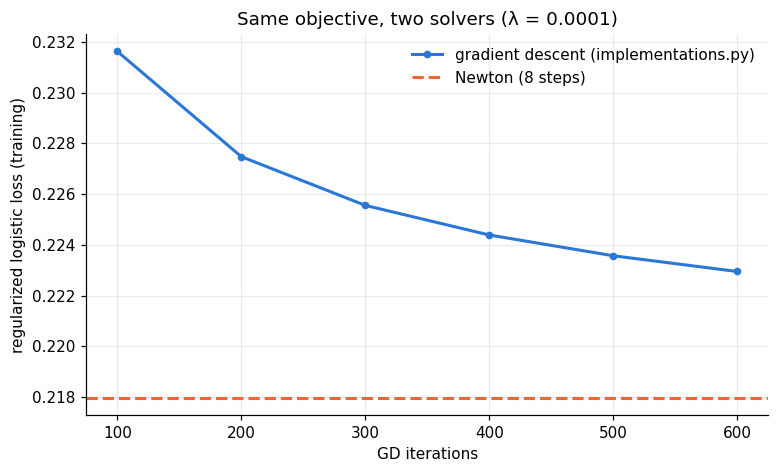

In [9]:
lam = 1e-4
objective = lambda w: np.mean(np.logaddexp(0, tx @ w) - y * (tx @ w)) + lam * w @ w
w_newton, n_steps = fe.reg_logistic_newton(y, tx, lam)
gamma = 4 / eigenvalues[-1]   # half of the stability limit 8/L
w, gd_objective = np.zeros(tx.shape[1]), []
for _ in range(6):
    w, _ = impl.reg_logistic_regression(y, tx, lam, w, 100, gamma)   # continue from w
    gd_objective.append(objective(w))
print(f"Newton ({n_steps} steps): objective = {objective(w_newton):.6f}")
print(f"GD (600 iterations, γ = {gamma:.4f}): objective = {gd_objective[-1]:.6f}")

fig, ax = plt.subplots()
ax.plot(100 * np.arange(1, 7), gd_objective, color=BLUE, marker="o", markersize=4,
        label="gradient descent (implementations.py)")
ax.axhline(objective(w_newton), color=ORANGE, linestyle="--", label=f"Newton ({n_steps} steps)")
ax.set_xlabel("GD iterations")
ax.set_ylabel("regularized logistic loss (training)")
ax.set_title(f"Same objective, two solvers (λ = {lam:g})")
ax.legend(frameon=False)
plt.show()

In [10]:
def newton(y, tx, params):
    return fe.reg_logistic_newton(y, tx, params["lambda_"], pos_weight=params["pos_weight"])[0]


logistic = {}
for lam in [1e-5, 1e-4, 1e-3]:
    for pos_weight in [1.0, 2.0]:
        logistic[(lam, pos_weight)] = run(tx, newton, {"lambda_": lam, "pos_weight": pos_weight},
                                          label=f"logistic, λ = {lam:g}, pos_weight = {pos_weight:g}")
LOGISTIC_BEST = max(logistic, key=lambda key: logistic[key]["f1_mean"])
print(f"\nbest: λ = {LOGISTIC_BEST[0]:g}, pos_weight = {LOGISTIC_BEST[1]:g}")

logistic, λ = 1e-05, pos_weight = 1            F1 = 0.4315 ± 0.0055   P = 0.351  R = 0.560   (86s)
logistic, λ = 1e-05, pos_weight = 2            F1 = 0.4316 ± 0.0052   P = 0.353  R = 0.556   (76s)
logistic, λ = 0.0001, pos_weight = 1           F1 = 0.4323 ± 0.0043   P = 0.364  R = 0.533   (86s)
logistic, λ = 0.0001, pos_weight = 2           F1 = 0.4325 ± 0.0043   P = 0.362  R = 0.536   (73s)
logistic, λ = 0.001, pos_weight = 1            F1 = 0.4320 ± 0.0047   P = 0.364  R = 0.532   (83s)
logistic, λ = 0.001, pos_weight = 2            F1 = 0.4326 ± 0.0046   P = 0.361  R = 0.541   (85s)

best: λ = 0.001, pos_weight = 2


## 8. Comparison and final model

AIcrowd scores are those of the submissions of each final configuration (one upload each, so about ±0.005 of
noise). All linear models end up close on these features; logistic regression is best on AIcrowd and is our final
model, reproduced by `run.py`.

model                                                                CV F1  AIcrowd
least squares, nb 01 features                              0.4107 ± 0.0069         
ridge, nb 01 features                                      0.4120 ± 0.0061         
ridge, final features, undersample 1:5                     0.4317 ± 0.0045    0.441
weighted least squares, c = 3                              0.4314 ± 0.0038    0.442
logistic (Newton), λ = 0.001, pos_weight = 2               0.4326 ± 0.0046    0.446


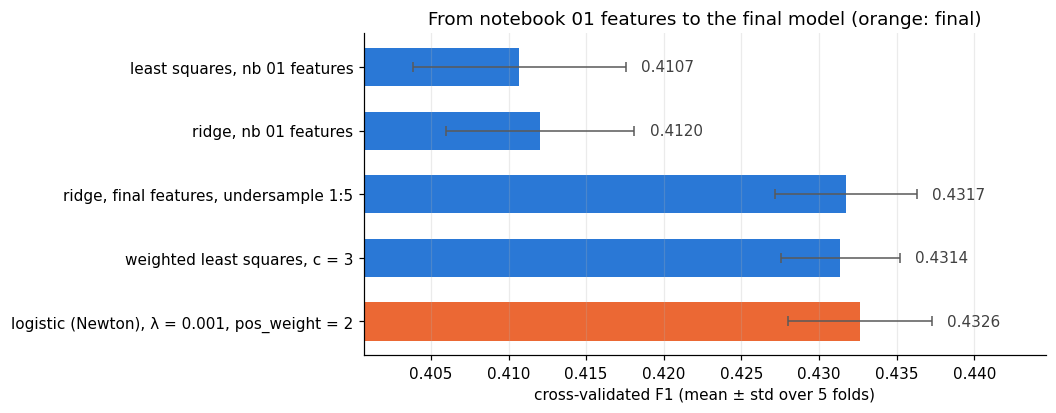

In [11]:
final_rows = [
    ("least squares, nb 01 features", ls_tuned, None),
    ("ridge, nb 01 features", ridge_base[best_lambda], None),
    (f"ridge, final features, undersample {ratio_label(RIDGE_BEST[1])}", ridge_grid[RIDGE_BEST], 0.441),
    (f"weighted least squares, c = {WLS_C:g}", weighted[WLS_C], 0.442),
    (f"logistic (Newton), λ = {LOGISTIC_BEST[0]:g}, pos_weight = {LOGISTIC_BEST[1]:g}", logistic[LOGISTIC_BEST], 0.446),
]
print(f"{'model':<58} {'CV F1':>15} {'AIcrowd':>8}")
for name, r, aicrowd in final_rows:
    print(f"{name:<58} {r['f1_mean']:.4f} ± {r['f1_std']:.4f} {'' if aicrowd is None else f'{aicrowd:.3f}':>8}")

labels = [row[0] for row in final_rows][::-1]
means = np.array([row[1]["f1_mean"] for row in final_rows])[::-1]
stds = np.array([row[1]["f1_std"] for row in final_rows])[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(labels, means, xerr=stds, color=[ORANGE] + [BLUE] * (len(labels) - 1), height=0.6,
        error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
for i, v in enumerate(means):
    ax.text(v + stds[i] + 0.001, i, f"{v:.4f}", va="center", color="0.25")
ax.set_xlim(means.min() - 0.01, means.max() + 0.012)
ax.set_xlabel("cross-validated F1 (mean ± std over 5 folds)")
ax.set_title("From notebook 01 features to the final model (orange: final)")
ax.grid(axis="y", visible=False)
plt.show()

The final model is retrained on all training rows and applied to the test set with the threshold chosen by
cross-validation. This is exactly what `run.py` does; the file written here is identical to `run.py`'s
`submission.csv`.

In [12]:
lam, pos_weight = LOGISTIC_BEST
w_final, _ = fe.reg_logistic_newton(y, tx, lam, pos_weight=pos_weight)
threshold = logistic[LOGISTIC_BEST]["threshold"]
test_predictions = np.where(tx_test @ w_final >= threshold, 1, -1)
oof_rate = np.mean(logistic[LOGISTIC_BEST]["oof_scores"] >= threshold)
print(f"threshold: score {threshold:.4f} = probability {impl.sigmoid(threshold):.4f}")
print(f"predicted positive rate: test {np.mean(test_predictions == 1):.4f}, out-of-fold {oof_rate:.4f}")

submission_path = PROJECT_ROOT / "submission_notebook05.csv"
create_csv_submission(raw["test_ids"], test_predictions, submission_path)
print(f"submission written to {submission_path}")

threshold: score -0.6323 = probability 0.3470
predicted positive rate: test 0.1331, out-of-fold 0.1325
submission written to /Users/ema/Desktop/EPFL/Machine Learning/ML_Project1/submission_notebook05.csv


## 9. Conclusions

- **The features matter much more than the model.** On the notebook 01 features every linear model reaches
  0.41-0.42; adding three feature groups that notebook 01 drops, squares and age/sex interactions brings all of
  them to about 0.43 in cross-validation and 0.44-0.45 on AIcrowd.
- **Tune the threshold, and rebalance mildly and inside the folds.** The F1-optimal threshold is far from 0.5;
  full rebalancing (1:1) hurts on the final features while mild undersampling or a positive weight of 2-3 helps
  least squares and ridge. Oversampling before splitting gives a meaningless F1 of 0.70.
- **Regularization barely matters** (N ≈ 330k ≫ D ≈ 1200): least squares is as good as ridge once redundant columns
  are removed, which is what ridge's penalty was silently doing.
- **Solve the logistic objective properly.** Newton's method reaches a lower objective in about 10 steps than
  gradient descent in 600; on the final features logistic regression gives our best submission (**0.446**).